--- Example 4.1 Results ---
Fullband Input SDR = 31.8604 dB


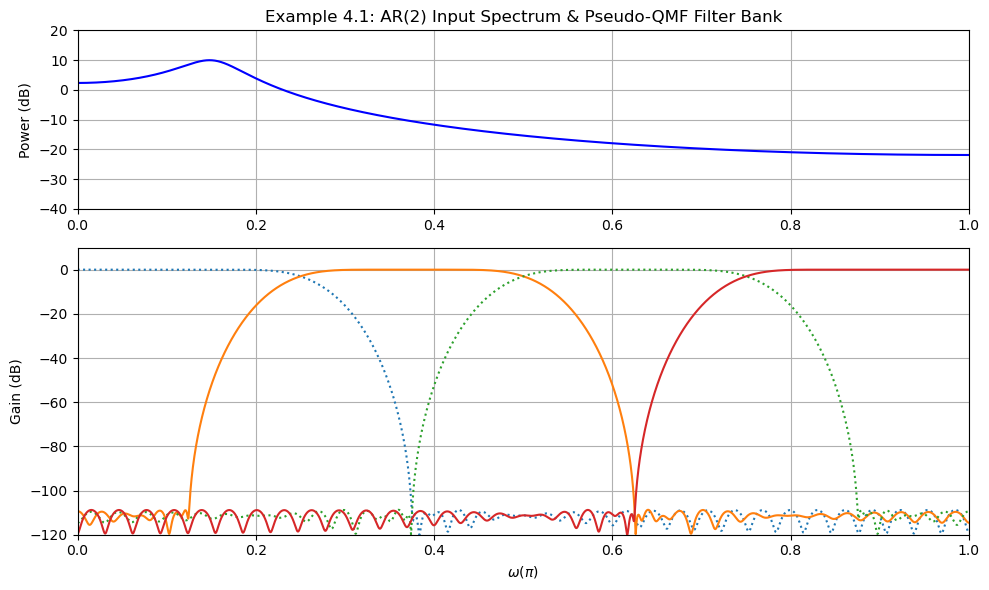

Subband 1 SDR = 14.9666 dB
Subband 2 SDR = 7.6115 dB
Subband 3 SDR = 2.8985 dB
Subband 4 SDR = 3.8431 dB


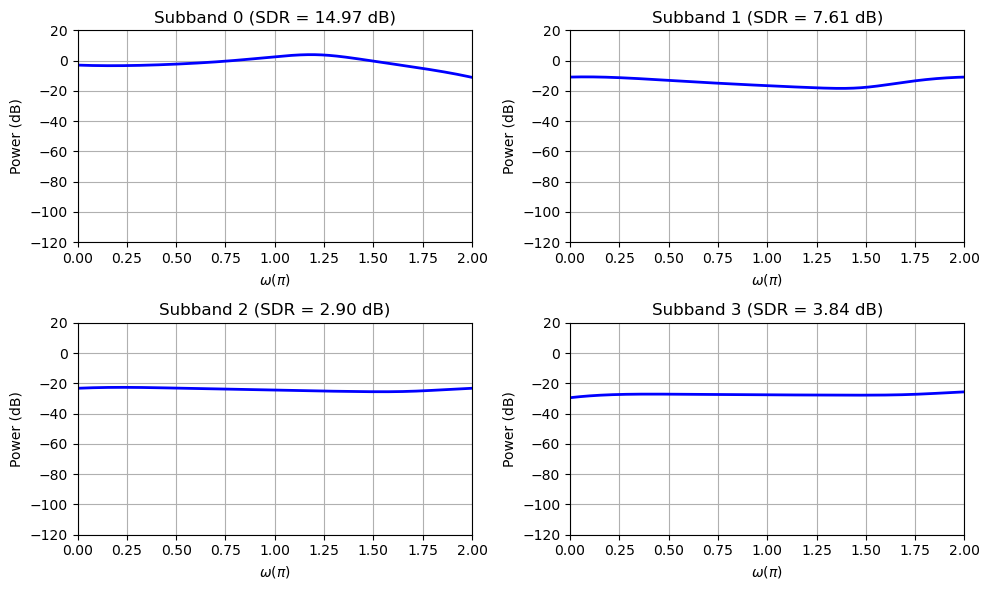

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import remez, lfilter


def opt_filter(filtorder: int, N: int):
    stopedge = 1.0 / N
    passedge = 1.0 / (4 * N)
    tol = 1e-6
    step = 0.1 * passedge
    way = -1
    pcost = 10.0
    flag = False

    while not flag:
        p = remez(filtorder + 1, [0, passedge, stopedge, 1.0], [1, 0], weight=[5, 1], fs=2.0)
        P = np.fft.fft(p, 4096)
        OptRange = int(np.floor(2048 / N))
        phi = np.zeros(OptRange)
        for k in range(1, OptRange + 1):
            phi[k - 1] = np.abs(P[OptRange - k + 1])**2 + np.abs(P[k - 1])**2
        tcost = np.max(np.abs(phi - 1.0))
        if tcost > pcost:
            step /= 2.0
            way = -way
        if np.abs(pcost - tcost) < tol:
            flag = True
        pcost = tcost
        passedge += way * step
    return p, passedge

def make_bank(p: np.ndarray, N: int):
    L = len(p)
    H = np.zeros((N, L))
    n = np.arange(L)
    for i in range(N):
        H[i, :] = 2 * p * np.cos((np.pi / N) * (i + 0.5) * (n - (L - 1) / 2.0) + ((-1)**i) * (np.pi / 4.0))
    return H

def FreqResp(H: np.ndarray, DFTpoint: int = 4096):
    if H.ndim == 1:
        H = H.reshape(1, -1)
    N, L = H.shape
    Hz = np.zeros((N, DFTpoint), dtype=complex)
    for k in range(N):
        Hz[k, :] = np.fft.fft(H[k, :], 2 * DFTpoint)[:DFTpoint]
    w = np.linspace(0, np.pi, DFTpoint)
    return Hz, w

def PSDecimation(X: np.ndarray, DFTpoint: int, D: int):
    delta_w = 2 * np.pi / DFTpoint
    XD = np.zeros((D, DFTpoint))

    for k in range(D):
        N_shift = int(np.round((2 * np.pi * k / D) / delta_w))
        x = X.copy()
        if N_shift > 0:
            x = np.roll(x, N_shift)
        XD[k, :] = x

    Npoint = int(np.round(DFTpoint / D))
    Npoint = (Npoint // 4) * 4
    XD_scaled = XD[:, :Npoint] / D
    xd = np.sum(XD_scaled, axis=0)

    delta_w_out = 2 * np.pi / Npoint
    w = np.arange(Npoint) * delta_w_out
    return xd, w, XD_scaled

# ==========================================
# 2. Example 4.1 Execution
# ==========================================
N = 4                          # Number of subbands
L = 16 * N                     # Filter length L = 64
D = N                          # Critical decimation D = 4

# AR(2) process signal generation
a = np.array([1.0, -1.6, 0.81])
np.random.seed(42)
wn = np.random.randn(4 * 80000)
un = lfilter([1.0], a, wn)

# Pseudo-QMF filter bank
hopt, passedge = opt_filter(L - 1, N)
H = make_bank(hopt, N)

DFTpoint = 4096
Hz, w = FreqResp(H, DFTpoint)
Hz_mag = np.abs(Hz)**2

# Input AR(2) spectrum
A_resp = np.fft.fft(a, 2 * DFTpoint)[:DFTpoint]
HzSig = 1.0 / (np.abs(A_resp)**2)
HzSig /= np.var(un)

# Calculate Fullband Spectral Dynamic Range (SDR)
SDR_in = np.max(10 * np.log10(HzSig + 1e-12)) - np.min(10 * np.log10(HzSig + 1e-12))
print(f"--- Example 4.1 Results ---")
print(f"Fullband Input SDR = {SDR_in:.4f} dB")

# Plot Input Spectrum & Filter Bank Response
plt.figure(figsize=(10, 6))
plt.subplot(5, 1, (1, 2))
plt.plot(w / np.pi, 10 * np.log10(HzSig + 1e-12), 'b')
plt.title('Example 4.1: AR(2) Input Spectrum & Pseudo-QMF Filter Bank')
plt.ylabel('Power (dB)')
plt.xlim([0, 1]); plt.ylim([-40, 20]); plt.grid(True)

plt.subplot(5, 1, (3, 5))
for k in range(N):
    if k % 2 == 1:
        plt.plot(w / np.pi, 10 * np.log10(Hz_mag[k, :] + 1e-12))
    else:
        plt.plot(w / np.pi, 10 * np.log10(Hz_mag[k, :] + 1e-12), ':')
plt.xlabel(r'$\omega (\pi)$'); plt.ylabel('Gain (dB)')
plt.xlim([0, 1]); plt.ylim([-120, 10]); plt.grid(True)
plt.tight_layout()
plt.show()

# Decimated Subband Spectra
plt.figure(figsize=(10, 6))
for i in range(N):
    plt.subplot(2, 2, i + 1)
    HzSub = HzSig * Hz_mag[i, :]
    xd, w_dec, _ = PSDecimation(HzSub, DFTpoint, D)
    plt.plot(w_dec / np.pi, 10 * np.log10(xd + 1e-12), 'b', linewidth=2.0)
    
    SDR_sub = np.max(10 * np.log10(xd + 1e-12)) - np.min(10 * np.log10(xd + 1e-12))
    print(f"Subband {i + 1} SDR = {SDR_sub:.4f} dB")
    
    plt.title(f'Subband {i} (SDR = {SDR_sub:.2f} dB)')
    plt.xlabel(r'$\omega (\pi)$'); plt.ylabel('Power (dB)')
    plt.xlim([0, 2]); plt.ylim([-120, 20]); plt.grid(True)

plt.tight_layout()
plt.show()

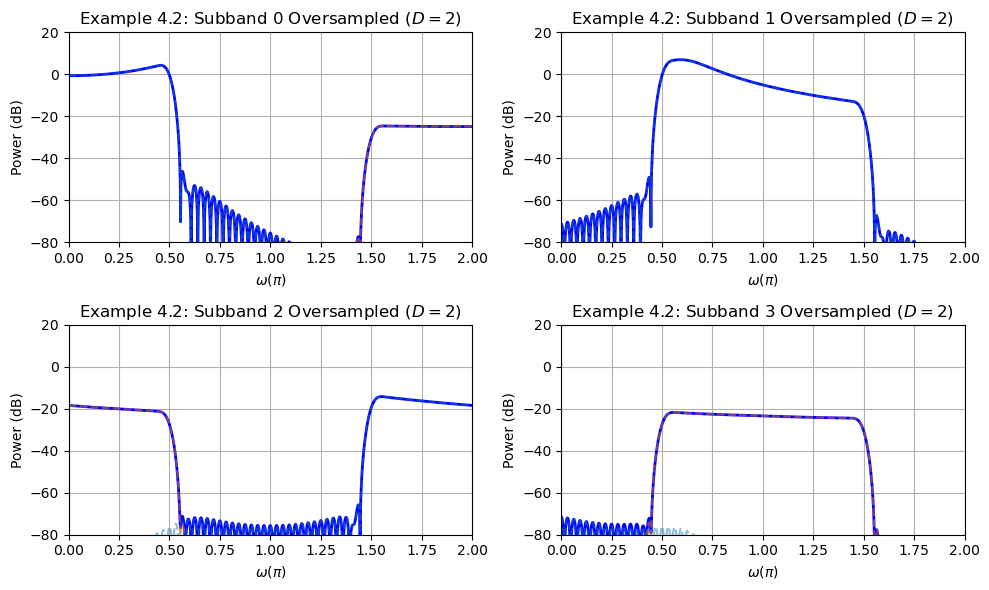

In [2]:
from scipy.signal import firwin

# ==========================================
# Helper Function (make_bank_DFT)
# ==========================================
def make_bank_DFT(p: np.ndarray, N: int):
    flen = len(p)
    H = np.zeros((flen, N // 2 + 1), dtype=complex)
    n = np.arange(flen)
    H[:, 0] = p
    H[:, N // 2] = p * ((-1)**n)
    for k in range(1, N // 2):
        H[:, k] = p * np.exp(1j * 2 * np.pi / N * k * n)
    D_mat = H[:, 1 : N // 2]
    H_full = np.hstack((H, np.conj(np.fliplr(D_mat))))
    return H_full.T  # Shape (N, L)

# ==========================================
# Example 4.2 Execution
# ==========================================
N = 4
L = 32 * N                     # Filter length L = 128
D_oversampled = N // 2         # Oversampling D = 2

hopt_dft = firwin(L, cutoff=1.0 / N, fs=2.0, window='hamming')
H_dft = make_bank_DFT(hopt_dft, N)

DFTpoint = 4096
Hz_dft = np.zeros((N, DFTpoint), dtype=complex)
for k in range(N):
    Hz_dft[k, :] = np.fft.fft(H_dft[k, :], DFTpoint)
Hz_dft_mag = np.abs(Hz_dft)**2

# Plot Oversampled Subband Spectrum (D = 2)
w_full = np.linspace(0, 2 * np.pi, DFTpoint, endpoint=False)

plt.figure(figsize=(10, 6))
for i in range(N):
    plt.subplot(2, 2, i + 1)
    HzSub = HzSig * Hz_dft_mag[i, :]
    xd, w_dec, XD = PSDecimation(HzSub, DFTpoint, D_oversampled)
    
    plt.plot(w_dec / np.pi, 10 * np.log10(xd + 1e-12), 'b', linewidth=2.0, label='Folded Spectrum')
    for m in range(D_oversampled):
        plt.plot(w_dec / np.pi, 10 * np.log10(XD[m, :] + 1e-12), '--', alpha=0.5)
        
    plt.title(f'Example 4.2: Subband {i} Oversampled ($D={D_oversampled}$)')
    plt.xlabel(r'$\omega (\pi)$'); plt.ylabel('Power (dB)')
    plt.xlim([0, 2]); plt.ylim([-80, 20]); plt.grid(True)

plt.tight_layout()
plt.show()